In [1]:
# Paths in this notebook are relative to the repository root. Opened from its own
# folder, the notebook moves there first; run from the root, this does nothing.
import os
from pathlib import Path
if not Path("tariff-lists").is_dir():
    os.chdir(next(p for p in Path.cwd().parents if (p / "tariff-lists").is_dir()))

In [2]:
import pandas as pd             # data package
import matplotlib.pyplot as plt # graphics 
import datetime as dt
import numpy as np

import requests, io             # internet and input tools  
import zipfile as zf            # zip file tools 
import os  

import pyarrow as pa
import pyarrow.parquet as pq

from bokeh.palettes import brewer, Spectral6
from bokeh.io import show, output_file
from bokeh.plotting import figure
from bokeh.models import ColumnDataSource, HoverTool, TabPanel, Tabs, LinearColorMapper
from bokeh.models import ColorBar
from bokeh.layouts import column, gridplot, row
from bokeh.transform import factor_cmap
from bokeh.models import NumeralTickFormatter, Title, Label, Paragraph, Div, CustomJSHover, BoxAnnotation
from bokeh.models import Button, CustomJS


In [3]:
recipricol_summary = pd.read_csv('country-by-time.csv')

recipricol_summary.date = pd.to_datetime(recipricol_summary.date, format="%Y-%m-%d")

recipricol_summary.set_index("date", inplace = True)

# Cross-section date for the bar chart and the headline average tariff: the most
# recent policy date on or before the run date, so both always describe the regime
# actually in force when the notebook is run. Future-dated actions already in the
# registry are correctly excluded until they take effect.
as_of = pd.Timestamp.today().normalize()
eligible_dates = recipricol_summary.index.unique()[recipricol_summary.index.unique() <= as_of]
CURRENT_DATE = eligible_dates.max() if len(eligible_dates) else recipricol_summary.index.min()

CURRENT_DATE_LABEL = f"{CURRENT_DATE:%B} {CURRENT_DATE.day}, {CURRENT_DATE.year}"

print(f"Run date {as_of.date()} -> using cross-section for {CURRENT_DATE.date()}")


# ── Caption policy text, derived from the action registry ────────────────
# Chart captions name the tariff authorities in force. Hand-maintained text goes
# stale the moment an action takes effect or lapses, so the list is derived from
# TARIFF_ACTIONS instead. The registry is imported from the main notebook by
# running its code cells up to tariff_imports — the same approach used in
# brazil-301-analysis.ipynb, and it avoids keeping a second copy of it here.
import json as _json
import io as _io

_engine_nb = _json.load(_io.open('code/make-tariff-by-country-by-time.ipynb', encoding='utf-8'))
for _cell in _engine_nb['cells']:
    if _cell['cell_type'] != 'code':
        continue
    _src = ''.join(_cell['source'])
    exec(compile(_src, 'tariff-engine', 'exec'))
    if 'def tariff_imports' in _src:
        break

AUTHORITY_PHRASES = {
    "Section 232": "Section 232 sectoral tariffs (steel, aluminum, autos, copper, metals restructuring)",
    "Section 122": "the Section 122 temporary import surcharge",
    "Section 301": "Section 301 country tariffs",
    "Section 338": "Section 338 retaliatory duties on Canada",
    "IEEPA":       "IEEPA country tariffs",
}


def authorities_in_force(as_of_date):
    """Phrases for the tariff authorities in force on a given date."""
    phrases = []
    for action in TARIFF_ACTIONS:
        start = pd.to_datetime(action["effective_date"])
        end = pd.to_datetime(action.get("end_date", "2100-01-01"))
        if not (start <= as_of_date <= end):
            continue
        for key, phrase in AUTHORITY_PHRASES.items():
            if key in action["authority"] and phrase not in phrases:
                phrases.append(phrase)

    # The Feb 20, 2026 EO revoked every IEEPA duty. Registry membership alone
    # does not capture that: the IEEPA phase-1 actions carry no end_date and are
    # instead zeroed by the revocation action, so drop IEEPA once it is in force.
    revoked = any("Ending Certain Tariff Actions" in action["reference"]
                  and pd.to_datetime(action["effective_date"]) <= as_of_date
                  for action in TARIFF_ACTIONS)
    if revoked:
        phrases = [p for p in phrases if p != AUTHORITY_PHRASES["IEEPA"]]

    return phrases


def phrase_list(items):
    """Join phrases into 'a, b, and c'."""
    if len(items) == 1:
        return items[0]
    if len(items) == 2:
        return f"{items[0]} and {items[1]}"
    return ", ".join(items[:-1]) + ", and " + items[-1]


POLICY_TEXT = phrase_list(authorities_in_force(CURRENT_DATE))
print(f"Caption policy text: {POLICY_TEXT}")

Run date 2026-11-25 -> using cross-section for 2026-10-30


Caption policy text: Section 232 sectoral tariffs (steel, aluminum, autos, copper, metals restructuring), Section 301 country tariffs, and Section 338 retaliatory duties on Canada


In [4]:
recipricol_summary.index.unique()

DatetimeIndex(['2025-02-04', '2025-03-06', '2025-03-12', '2025-04-03',
               '2025-04-05', '2025-04-09', '2025-04-10', '2025-04-11',
               '2025-05-12', '2025-06-03', '2025-08-07', '2025-10-14',
               '2025-11-01', '2025-11-14', '2025-12-04', '2026-02-07',
               '2026-02-20', '2026-02-24', '2026-04-06', '2026-07-22',
               '2026-07-24', '2026-07-31', '2026-08-22', '2026-09-15',
               '2026-10-30', '2027-01-01', '2027-02-01'],
              dtype='datetime64[ns]', name='date', freq=None)

In [5]:
foo = recipricol_summary.loc[CURRENT_DATE].copy(deep=True)

foo.sort_values(by='total imports', ascending=False, inplace=True)

foo[0:20].head(20)

foobar = foo[0:50].copy(deep=True)

foobar.rename({"effective tariff": "2025 tariff increase"}, axis=1, inplace=True)

avg_tariff = ( foobar["2025 tariff increase"]*foobar["total imports"] ).sum() / foobar["total imports"].sum() + 2.3 

print("Average Tariff Rate: ", avg_tariff)

Average Tariff Rate:  11.46350479968902


In [6]:
foobar.reset_index(inplace=True, drop=True)

In [7]:
foobar.head(20)

,country_name,2025 tariff increase,total imports,2024 tariff
0,EUROPEAN UNION,8.403241,5.974732e+11,1.229078
1,MEXICO,7.656373,5.034386e+11,0.248399
2,CHINA,11.935632,4.294258e+11,10.865955
3,CANADA,7.966313,4.116938e+11,0.100472
4,JAPAN,13.328729,1.513400e+11,1.508006
5,VIETNAM,10.254839,1.413612e+11,3.774345
6,"KOREA, SOUTH",13.606195,1.304587e+11,0.190750
7,TAIWAN,5.491114,1.152741e+11,0.938144
8,INDIA,9.654074,8.773522e+10,2.400663
9,UNITED KINGDOM,8.149795,6.820597e+10,0.956848


In [8]:
def make_empty_df():

    empty_df = pd.DataFrame(columns=['country_name',"2025 tariff increase", 'total imports',"2024 tariff",])

    empty_df.loc[0, 'country_name'] = ''
    
    empty_df.loc[0, 'total imports'] = 0.0

    empty_df.loc[0, '2025 tariff increase'] = 0.0

    empty_df.loc[0, '2024 tariff'] = 0.0

    return empty_df

In [9]:
def make_source(df):
    
    df["position"] = df.reset_index().index.values
        
    df["hover_label"] = (df["total imports"]/1000000000).map('{:,.1f}'.format)
        
    df["hover_label_2"] = (df["2025 tariff increase"]).map('{:,.1f}'.format)
    
    df["hover_label_3"] = (df["2024 tariff"]).map('{:,.1f}'.format)

    source = ColumnDataSource(df)
    
    return source

In [10]:
def make_bar_chart(df):

    height = int(1.15*533)
    width = int(1.15*750)

    source = make_source(df)
        
    p = figure(height=height, width=width, 
               title= "U.S. Tariff Increase Since Jan 20th by Country of Origin (Top 20 by Import Value)", x_range=df['country_name'],
           toolbar_location = 'below',
           tools = "reset")
            
    p.vbar(x = "country_name", top = "2025 tariff increase", width = 0.6, alpha = 0.65,
       hatch_pattern = " ",hatch_alpha = 0.10, color = "red",
       source = source)
    
##########################################################################
    TIMETOOLTIPS = """
    <div style="background-color:#F5F5F5; opacity: 0.95; border: 0px 0px 0px 0px">
        <div style = "text-align:left;">
            <span style="font-size: 13px; font-weight: bold">@country_name</span>
        </div>
        <div style = "text-align:left;">
            <span style="font-size: 13px; font-weight: bold">2024 Imports: $@hover_label Billion</span>
        </div>
        <div style = "text-align:left;">
            <span style="font-size: 13px; font-weight: bold">Applied Tariff Increase: @hover_label_2%</span>
        </div>
        <div style = "text-align:left;">
            <span style="font-size: 13px; font-weight: bold">2024 Applied Tariff: @hover_label_3%</span>
        </div>
    </div>
    """

    p.add_tools(HoverTool(tooltips = TIMETOOLTIPS))
##########################################################################

    df["position"] = df.reset_index().index.values
    mid_idx = len(df['position']) // 2
    x_val = df['position'].iloc[mid_idx]
    y_val = df["2025 tariff increase"].max() * .85

    mytext = Label(x=x_val, y=y_val, text='U.S. Average Tariff:', 
               text_font_size="2em", text_font_style="bold",
               x_units='data', y_units='data')

    # p.add_layout(mytext)

    mytext2 = Label(x=x_val, y=y_val * 0.75, text=str(round(avg_tariff,1)) + '%',
                text_font_size="6em", text_font_style="bold",
                x_units='data', y_units='data')

    # p.add_layout(mytext2)

    p.xgrid.grid_line_color = None
    
    p.title.text_font_size = '14pt'
    p.xaxis.major_tick_line_color = None  # turn off x-axis major ticks
    p.xaxis.minor_tick_line_color = None  # turn off x-axis minor ticks


    p.xaxis.major_label_text_font_size = '7pt'  # turn off x-axis tick labels
    p.xaxis.major_label_orientation = 0.75 

    p.yaxis.formatter = NumeralTickFormatter(format="(0. a)")
    p.yaxis.minor_tick_line_color = None
    p.y_range.start = 0 
    
    p.y_range.end = df["2025 tariff increase"].max() + 0.10*df["2025 tariff increase"].max()
    
    p.border_fill_color = background    
    
    p.background_fill_color = background 
    p.background_fill_alpha = 0.75    
    
    p.toolbar.autohide = True
    
    p.outline_line_color = None
    p.sizing_mode = "scale_width"

    return p


In [11]:
crl = ["darkblue","slategray","slategray","crimson","crimson"]

background = "#ffffff"

In [12]:
fed_tax = pd.read_csv("data/federal-tax-duty.csv",skiprows=3, nrows=17)
# from Table 3.5. Taxes on Production and Imports

fed_duties = fed_tax.iloc[15,2:]

# Convert the Series to a DataFrame
fed_duties_df = fed_duties.to_frame()

# # Optionally, rename the column for clarity
fed_duties_df.columns = ['duty']

fed_duties_df.index.rename('time', inplace=True)

# # # Reset the index if needed
fed_duties_df.reset_index(inplace=True)

fed_duties_df["time"] = pd.to_datetime(fed_duties_df["time"], format="%Y")

# Extract only the year and overwrite the 'time' column
fed_duties_df["time"] = fed_duties_df["time"].dt.year

######################################################################################

NIPA_imports = pd.read_csv("data/NIPA-imports.csv",skiprows=3, nrows=20)
# from Table 4.1. Foreign Transactions in the National Income and Product Accounts

imports = NIPA_imports.iloc[19,2:]

imports_df = imports.to_frame()

# Optionally, rename the column for clarity
imports_df.columns = ['import_value']

# Rename the index
imports_df.index.rename('time', inplace=True)

# Reset the index if needed
imports_df.reset_index(inplace=True)

# Ensure the 'time' column is in datetime format
imports_df["time"] = pd.to_datetime(imports_df["time"], format="%Y")

# Extract only the year and overwrite the 'time' column
imports_df["time"] = imports_df["time"].dt.year

########################################################################################

merged_df = pd.merge(fed_duties_df, imports_df, on='time', how='inner')

merged_df["duty"] = merged_df["duty"].astype(float)
merged_df["import_value"] = merged_df["import_value"].astype(float)

merged_df["tariff"] = ( merged_df["duty"] / merged_df["import_value"] ) * 100

# Create a new row with the year 2024 and a tariff value
# comes from www.tradewartracker.com
new_row = {'time': "2024", 'duty': 0, 'import_value': 0, 'tariff': 2.4}
merged_df = pd.concat([merged_df, pd.DataFrame([new_row])], ignore_index=True)

# Create a new row with the year 2026 and a tariff value
# comes from www.tradewartracker.com
new_row = {'time': "2026", 'duty': 0, 'import_value': 0, 'tariff': avg_tariff}
merged_df = pd.concat([merged_df, pd.DataFrame([new_row])], ignore_index=True)

# Ensure the 'time' column is in datetime format
merged_df["time"] = pd.to_datetime(merged_df["time"], format="%Y")

In [13]:
avg_tariff

np.float64(11.46350479968902)

In [14]:
def make_tariff_time(df):

    height = int(1.15*533)
    width = int(1.15*750)

    source = ColumnDataSource(df)
        
    p = figure(x_axis_type="datetime", height=height, width=width, title= "U.S. Tariff Rate 1929-2026",
           toolbar_location = 'below',
           tools = "reset")
            
    p.line(x = "time", y = "tariff",
                line_width=10, line_alpha=0.75, line_color = "slategray",
                hover_line_alpha=0.75, hover_line_width = 12,
                hover_line_color= "crimson", source = source)
    
##########################################################################
    TIMETOOLTIPS = """
            <div style="background-color:#F5F5F5; opacity: 0.95; border: 5px 5px 5px 5px;">
            <div style = "text-align:left;">
            <span style="font-size: 13px; font-weight: bold"> Average Tariff
             </span>
             </div>
             <div style = "text-align:left;">"""
    

    TIMETOOLTIPS = TIMETOOLTIPS + """
            <span style="font-size: 13px; font-weight: bold"> $x{%Y}:  $y{0.0}%</span>   
            </div>
            </div>
            """
        
    p.add_tools(HoverTool(tooltips = TIMETOOLTIPS, line_policy='nearest', formatters={'$x': 'datetime'}))

##########################################################################

    p.xgrid.grid_line_color = None
    
    p.title.text_font_size = '16pt'

    p.xaxis.major_tick_line_color = None  # turn off x-axis major ticks
    p.xaxis.minor_tick_line_color = None  # turn off x-axis minor ticks

    p.x_range.start = pd.to_datetime("1928-01-01")
    p.xaxis.major_label_text_font_size = '12pt'  # turn off x-axis tick labels
    p.xaxis.major_label_orientation = 0.75 

    p.yaxis.formatter = NumeralTickFormatter(format="(0. a)")
    p.y_range.start = 0 
    p.y_range.end = 30.0 

    p.yaxis.major_label_text_font_size = "12pt"  # Increase font size
    
    
    p.border_fill_color = background    
    
    p.background_fill_color = background 
    p.background_fill_alpha = 0.75    
    
    p.toolbar.autohide = True
    
    p.outline_line_color = None
    p.sizing_mode = "scale_width"

    return p

In [15]:
daily_tariff = pd.read_csv("daily-tariff-latest-data.csv", usecols=["date", "import_weighted_avg_tariff"])

daily_tariff["date"] = pd.to_datetime(daily_tariff["date"])

# 1. Set date as index if not already
daily_tariff = daily_tariff.set_index('date')

# # 2. Create a regular date range (e.g., daily)
# full_range = pd.date_range(daily_tariff.index.min(), pd.Timestamp.now(), freq='D')

# # 3. Reindex and forward-fill missing values
# daily_tariff_filled = daily_tariff.reindex(full_range).ffill()

# # 4. Reset index for plotting
# daily_tariff_filled = daily_tariff_filled.reset_index().rename(columns={'index': 'date'})


In [16]:
pd.Timestamp.now().floor('D')

Timestamp('2026-11-25 00:00:00')

In [17]:
daily_tariff.tail()

,import_weighted_avg_tariff
date,
2027-02-27,14.392528
2027-02-28,14.392528
2027-03-01,14.392528
2027-03-02,14.392528
2027-03-03,14.392528


In [18]:
def make_tariff_daily(df):

    height = int(1.15*533)
    width = int(1.15*750)

    current_tariff = df['import_weighted_avg_tariff'].iloc[-1]
        
    p = figure(x_axis_type="datetime", height=height, width=width, 
               title= "Today's Tariff Rate: " + str(round(avg_tariff,1)) + "%",
           toolbar_location = 'below',
           tools = "reset")

    source = ColumnDataSource(df.loc["2025-01":])

    p.line(x = "date", y = "import_weighted_avg_tariff",
                line_width=10, line_alpha=0.75, line_color = "crimson",
                hover_line_alpha=0.75, hover_line_width = 12,
                hover_line_color= "crimson", source = source)

##########################################################################
    TIMETOOLTIPS = """
            <div style="background-color:#F5F5F5; opacity: 0.95; border: 5px 5px 5px 5px;">
            <div style = "text-align:left;">
            <span style="font-size: 13px; font-weight: bold"> Average Tariff
             </span>
             </div>
             <div style = "text-align:left;">"""
    

    TIMETOOLTIPS = TIMETOOLTIPS + """
            <span style="font-size: 13px; font-weight: bold"> $x{%Y-%m-%d}:  $y{0.0}%</span>   
            </div>
            </div>
            """
        
    p.add_tools(HoverTool(tooltips = TIMETOOLTIPS, line_policy='nearest', formatters={'$x': 'datetime'}))

##########################################################################

    p.xgrid.grid_line_color = None
    
    p.title.text_font_size = '20pt'

    p.xaxis.major_tick_line_color = None  # turn off x-axis major ticks
    p.xaxis.minor_tick_line_color = None  # turn off x-axis minor ticks

    p.x_range.start = pd.to_datetime("2025-01-01")
    p.xaxis.major_label_text_font_size = '12pt'  # turn off x-axis tick labels
    p.xaxis.major_label_orientation = 0.75 

    p.yaxis.formatter = NumeralTickFormatter(format="(0. a)")
    p.y_range.start = 0 
    p.y_range.end = 35.0 

    p.yaxis.major_label_text_font_size = "12pt"  # Increase font size

    
    p.border_fill_color = background    
    
    p.background_fill_color = background 
    p.background_fill_alpha = 0.75    
    
    p.toolbar.autohide = True
    
    p.outline_line_color = None
    p.sizing_mode = "scale_width"

    y_val = df['import_weighted_avg_tariff'].iloc[-1]
    
    return p


In [19]:
foo = recipricol_summary.loc[CURRENT_DATE].copy(deep=True)

foo.sort_values(by='total imports', ascending=False, inplace=True)

foo[0:20].head(20)

foobar = foo[0:20].copy(deep=True)

foobar.rename({"effective tariff": "2025 tariff increase"}, axis=1, inplace=True)

foobar.reset_index(inplace=True, drop=True)

bar = make_empty_df()

foobar = pd.concat([bar, foobar], ignore_index=True)

p1 = make_bar_chart(foobar)


####################################################

p2 = make_tariff_time(merged_df)

p3 = make_tariff_daily(daily_tariff)

output_file('.\\docs\\' + "reciprocal-new-steel.html")

div1 = Div(text = f"""Each bar represents the increase in the trade-weighted applied tariff for each country since January 20th, as of
        {CURRENT_DATE_LABEL}, including {POLICY_TEXT}, and known deals (EU, Japan, South Korea, etc.). 
           The average tariff reflects the trade-weighted average of all tariffs, including the existing 2.3% applied tariff as of February 2025.
""", max_width= int(1.15*750), background = background )

div4 = Div(text = """Each bar represents the increase in the trade-weighted applied tariff for each country since January 20th 
           **not** including known deals (EU, Japan, etc.). 
           The average tariff reflects the trade-weighted average of all tariffs, including the existing 2.3% applied tariff as of February 2025.
""", max_width= int(1.15*750), background = background )


div2 = Div(text = f"""This chart shows the average U.S. tariff rate from 1929 to the present.
The average tariff is calculated as collected duties (from NIPA Table 3.5) divided by the value of goods imports (from NIPA Table 4.1).
The {CURRENT_DATE.year} estimated tariff rate, as of {CURRENT_DATE_LABEL}, includes {POLICY_TEXT},
and surviving bilateral deals. These estimates account for exemptions where applicable.   
""", max_width= int(1.15*750), background = background )

# What the daily line shows beyond the run date. The daily file carries policy dates
# that have not arrived yet: steps already scheduled in law and, from an assumed date,
# the Section 301 tariffs proposed on Nov 25, 2026. The caption names each one that is
# still ahead, so it stays right as the dates pass. Add a note for any new future date.
FUTURE_NOTES = {
    "2027-01-01": "the Section 232 rates on furniture and kitchen cabinets rise on January 1, 2027, as scheduled",
    "2027-02-01": ("from February 1, 2027 it includes the Section 301 tariffs that USTR proposed on "
                   "November 25, 2026 for 14 economies. These are not in force: the rates are the proposed "
                   "ceilings and the start date is an assumption"),
}
_ahead = [d for d in recipricol_summary.index.unique().sort_values() if d > CURRENT_DATE]
if _ahead:
    AHEAD_TEXT = ("Beyond that date the line shows changes that have not yet taken effect: "
                  + "; ".join(FUTURE_NOTES.get(f"{d:%Y-%m-%d}", f"a change dated {d:%B} {d.day}, {d.year}")
                              for d in _ahead) + ".")
else:
    AHEAD_TEXT = "It is held flat beyond that date."

div3 = Div(text = f"""This plot displays the average daily tariff rate since January 2025. The crimson line shows the 
           tariff rate in force through the latest policy date ({CURRENT_DATE_LABEL}). {AHEAD_TEXT} 
           The average tariff reflects the trade-weighted average of all tariffs, including the existing 2.3% applied tariff as of February 2025.  
""", max_width= int(1.15*750), background = background )

# tab1_layout = column(p1, div1, sizing_mode="scale_width")
tab2_layout = column(p2, div2, sizing_mode="scale_width")
tab3_layout = column(p3, div3, sizing_mode="scale_width")


# Create tabs
# tab1 = TabPanel(child=tab1_layout, title="Tariffs by Country")
tab2 = TabPanel(child=tab2_layout, title="Tariffs Over Time")
tab3 = TabPanel(child=tab3_layout, title="Daily Tariff Rate")

# Combine tabs into a Tabs layout
tabs = Tabs(tabs=[tab3, tab2], tabs_location="above")

show(tabs)

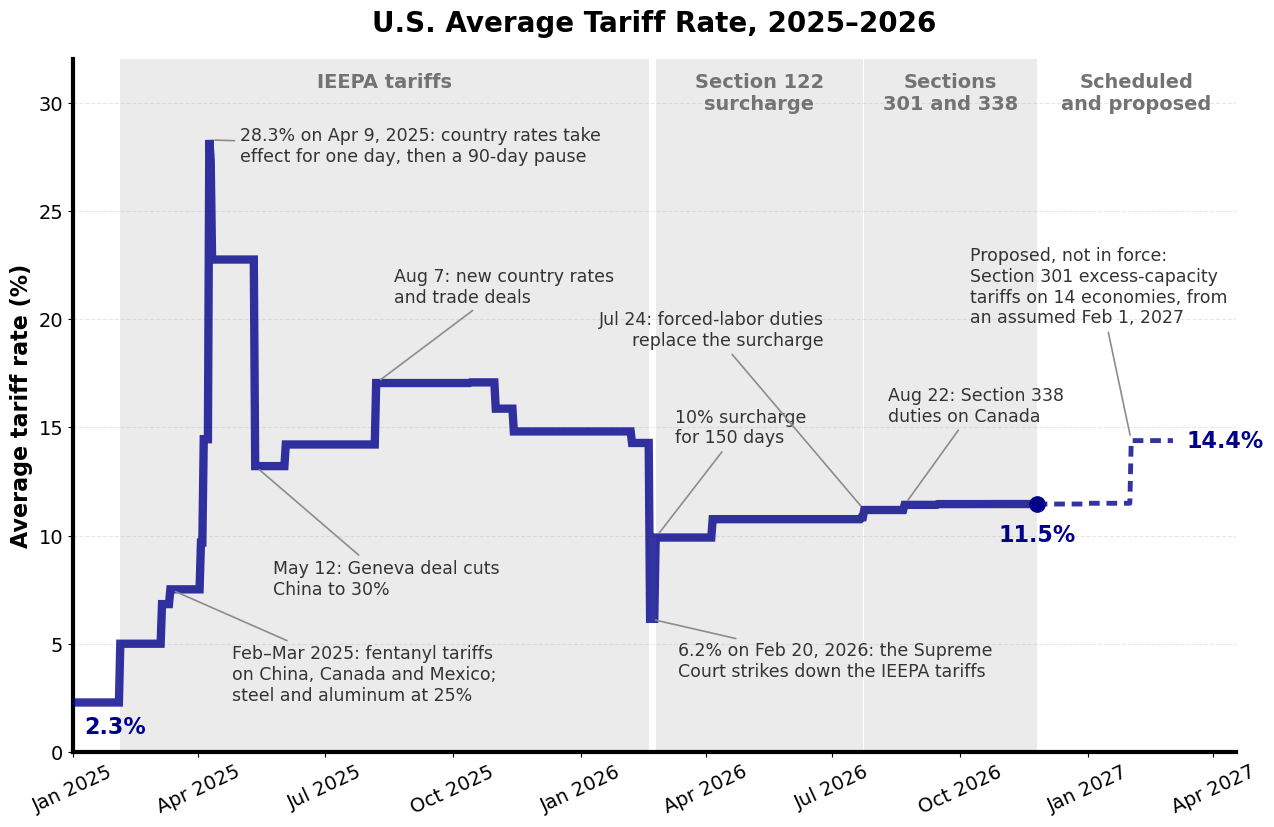

In [20]:
# ── README header figure ─────────────────────────────────────────────────
# figures/tariff-fig.png at the top of README.md: the daily national average, annotated
# with the three policy periods and the main events, in the house figure style.
# Each label reads its rate from the series, so only a new action needs a new
# EVENTS entry. The solid line stops at the run date. If the daily file holds
# changes dated after it (scheduled steps, or the proposed Section 301 tariffs
# from their assumed date), they are drawn dashed and labelled; a flat
# forward-filled tail is not drawn, because it is not data.
%matplotlib inline
import matplotlib.dates as mdates

plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.linewidth': 3, 'axes.labelweight': 'bold', 'axes.titleweight': 'bold',
    'axes.titlesize': 20, 'axes.labelsize': 16,
    'xtick.labelsize': 14, 'ytick.labelsize': 14,
    'legend.frameon': False, 'legend.fontsize': 12,
    'grid.alpha': 0.3, 'grid.linestyle': '--', 'savefig.bbox': 'tight',
})
LINE = 'darkblue'
NOTE = '#333333'

as_of = pd.Timestamp.today().normalize()
series = daily_tariff.loc[:as_of, "import_weighted_avg_tariff"]
ahead = daily_tariff.loc[as_of:, "import_weighted_avg_tariff"]
has_ahead = ahead.nunique() > 1          # a change is dated after the run date

# Policy periods shaded behind the line: (start, end, label).
PERIODS = [
    ("2025-02-04", "2026-02-19", "IEEPA tariffs"),
    ("2026-02-24", "2026-07-23", "Section 122\nsurcharge"),
    ("2026-07-24", as_of, "Sections\n301 and 338"),
]

# Event callouts: (date, label, text x, text y, alignment). {v} is the rate that day.
EVENTS = [
    ("2025-03-12", "Feb–Mar 2025: fentanyl tariffs\non China, Canada and Mexico;\nsteel and aluminum at 25%",
     "2025-04-25", 3.6, "left"),
    ("2025-04-09", "{v:.1f}% on Apr 9, 2025: country rates take\neffect for one day, then a 90-day pause",
     "2025-05-01", 28.0, "left"),
    ("2025-05-12", "May 12: Geneva deal cuts\nChina to 30%",
     "2025-05-25", 8.0, "left"),
    ("2025-08-07", "Aug 7: new country rates\nand trade deals",
     "2025-08-20", 21.5, "left"),
    ("2026-02-20", "{v:.1f}% on Feb 20, 2026: the Supreme\nCourt strikes down the IEEPA tariffs",
     "2026-03-12", 4.2, "left"),
    ("2026-02-24", "10% surcharge\nfor 150 days",
     "2026-03-10", 15.0, "left"),
    ("2026-07-24", "Jul 24: forced-labor duties\nreplace the surcharge",
     "2026-06-25", 19.5, "right"),
    ("2026-08-22", "Aug 22: Section 338\nduties on Canada",
     "2026-08-10", 16.0, "left"),
]

# Callouts for changes dated after the run date, same fields as EVENTS. Drawn only
# while the date is still ahead; once an entry is in force, move it to EVENTS.
FUTURE_EVENTS = [
    ("2027-02-01", "Proposed, not in force:\nSection 301 excess-capacity\ntariffs on 14 economies, from\nan assumed Feb 1, 2027",
     "2026-10-08", 21.5, "left"),
]

fig, ax = plt.subplots(figsize=(15, 9))
x_end = (ahead if has_ahead else series).index[-1] + pd.Timedelta(days=45)   # right edge of the axis

ymax = 32
for start, end, label in PERIODS:
    s, e = pd.Timestamp(start), pd.Timestamp(end)
    ax.axvspan(s, e, color="0.92", zorder=0, lw=0)
    ax.text(s + (e - s) / 2, ymax - 0.6, label, ha="center", va="top",
            fontsize=14, fontweight="bold", color="0.45")

ax.plot(series.index, series.values, color=LINE, lw=6, alpha=0.8,
        solid_joinstyle="miter", zorder=3)
if has_ahead:
    ax.plot(ahead.index, ahead.values, color=LINE, lw=3.5, alpha=0.8,
            linestyle=(0, (2.2, 1.4)), zorder=3)
    ax.text(as_of + (x_end - as_of) / 2, ymax - 0.6, "Scheduled\nand proposed",
            ha="center", va="top", fontsize=14, fontweight="bold", color="0.45")

callouts = EVENTS + [e for e in FUTURE_EVENTS
                     if has_ahead and as_of < pd.Timestamp(e[0]) <= ahead.index[-1]]
both = pd.concat([series, ahead.iloc[1:]])
for date, text, tx, ty, ha in callouts:
    d = pd.Timestamp(date)
    v = both.loc[d]
    ax.annotate(text.format(v=v), xy=(d, v), xytext=(pd.Timestamp(tx), ty),
                ha=ha, va="center", fontsize=12.5, color=NOTE,
                arrowprops=dict(arrowstyle="-", color="0.55", lw=1.2, shrinkA=2, shrinkB=4),
                zorder=4)

# Start and end-of-line values, color-matched to the line. With a dashed tail the
# value in force today sits under the end of the solid line, and the tail gets its own.
if has_ahead:
    ax.plot([series.index[-1]], [series.iloc[-1]], marker="o", ms=11, color=LINE, zorder=5)
    ax.annotate(f"{series.iloc[-1]:.1f}%", xy=(series.index[-1], series.iloc[-1]),
                xytext=(0, -22), textcoords="offset points", ha="center",
                fontsize=16, fontweight="bold", color=LINE, va="center")
    ax.annotate(f"{ahead.iloc[-1]:.1f}%", xy=(ahead.index[-1], ahead.iloc[-1]),
                xytext=(10, 0), textcoords="offset points",
                fontsize=16, fontweight="bold", color=LINE, va="center")
else:
    ax.annotate(f"{series.iloc[-1]:.1f}%", xy=(series.index[-1], series.iloc[-1]),
                xytext=(10, 0), textcoords="offset points",
                fontsize=16, fontweight="bold", color=LINE, va="center")
ax.annotate(f"{series.iloc[0]:.1f}%", xy=(series.index[0], series.iloc[0]),
            xytext=(8, -18), textcoords="offset points", ha="left",
            fontsize=16, fontweight="bold", color=LINE, va="center")

ax.set_xlim(series.index[0], x_end)
ax.set_ylim(0, ymax)
ax.set_ylabel("Average tariff rate (%)")
ax.set_title("U.S. Average Tariff Rate, 2025–2026", pad=20)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y")

fig.savefig("figures/tariff-fig.png", dpi=120)
fig.savefig("figures/tariff-fig.pdf")
plt.show()

In [21]:
foobar.head(20)

,country_name,2025 tariff increase,total imports,2024 tariff,position,hover_label,hover_label_2,hover_label_3
0,,0.0,0.0,0.0,0,0.0,0.0,0.0
1,EUROPEAN UNION,8.403241,597473236377.0,1.229078,1,597.5,8.4,1.2
2,MEXICO,7.656373,503438605302.0,0.248399,2,503.4,7.7,0.2
3,CHINA,11.935632,429425828419.0,10.865955,3,429.4,11.9,10.9
4,CANADA,7.966313,411693824741.0,0.100472,4,411.7,8.0,0.1
5,JAPAN,13.328729,151340030810.0,1.508006,5,151.3,13.3,1.5
6,VIETNAM,10.254839,141361159091.0,3.774345,6,141.4,10.3,3.8
7,"KOREA, SOUTH",13.606195,130458735626.0,0.19075,7,130.5,13.6,0.2
8,TAIWAN,5.491114,115274122243.0,0.938144,8,115.3,5.5,0.9
9,INDIA,9.654074,87735219365.0,2.400663,9,87.7,9.7,2.4
